<a href="https://colab.research.google.com/github/edoardo2496/data_science_portfolio/blob/main/Titanic-What-If-Scenario-Engine/Titanic_WhatIf_Engine.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Section 1. Setup and Libraries

##In this section, we import all the necessary libraries for analysis, preprocessing, modeling, and evaluation.

In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, RocCurveDisplay

# Configurazione grafica
sns.set_theme(style="whitegrid")
import warnings
warnings.filterwarnings('ignore')

# Section 2. Data Loading and Exploratory Data Analysis (EDA)

##We load the dataset directly from Seaborn and perform an exploratory analysis aimed at identifying missing values and key relationships.

In [10]:
# Caricamento del dataset
df_titanic = sns.load_dataset('titanic')

# Anteprima dei dati
display(df_titanic.head())
print("Dimensioni del dataset:", df_titanic.shape)

# Informazioni generali e valori mancanti
display(df_titanic.info())
display(df_titanic.isnull().sum()[df_titanic.isnull().sum() > 0])

# Analisi rapida: Tasso di sopravvivenza per sesso e classe
display(df_titanic.groupby(['sex', 'pclass'])['survived'].mean().reset_index())

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


Dimensioni del dataset: (891, 15)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    object  
 8   class        891 non-null    category
 9   who          891 non-null    object  
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    object  
 13  alive        891 non-null    object  
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), object(5)
memory usage: 80.7+ KB


None

,0
age,177
embarked,2
deck,688
embark_town,2


,sex,pclass,survived
0,female,1,0.968085
1,female,2,0.921053
2,female,3,0.500000
3,male,1,0.368852
4,male,2,0.157407
5,male,3,0.135447


# Section 3. Data Preprocessing and Feature Engineering

##We clean the dataset by removing redundant columns (e.g., 'alive' which is identical to 'survived', or duplicates like 'class' and 'embark_town') and set up our transformations using pipelines.

In [11]:
# Pulizia delle colonne ridondanti o con troppi valori mancanti direttamente da df_titanic
df = df_titanic.drop(columns=['alive', 'class', 'embark_town', 'deck', 'boat', 'body', 'home.dest'], errors='ignore')

# Separazione tra Features (X) e Target (y)
X = df.drop(columns=['survived'])
y = df['survived']

# Identificazione delle feature numeriche e categoriche
numeric_features = ['age', 'sibsp', 'parch', 'fare']
categorical_features = ['sex', 'embarked', 'who', 'adult_male', 'alone']

# Pipeline di trasformazione per le variabili numeriche
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Pipeline di trasformazione per le variabili categoriche
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

# Unione dei trasformatori tramite ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ])

# Section 4. Train-Test Split (Stratified)

##In this section, we split the data into training and testing sets. We use stratified splitting to ensure that the proportion of survived and non-survived passengers is representative and consistently balanced across both sets.

In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(f"Train set shape: {X_train.shape}")
print(f"Test set shape: {X_test.shape}")

Train set shape: (712, 10)
Test set shape: (179, 10)


# Section 5. Baseline Models Training

##In this section, we build and train our baseline models. We will combine our feature preprocessing pipeline with a machine learning classifier, such as a Random Forest, to establish a performance baseline on our training data.

In [13]:
# Creazione della pipeline completa con Random Forest
pipeline_rf = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(random_state=42))
])

# Addestramento del modello
pipeline_rf.fit(X_train, y_train)

# Predizioni sul test set
y_pred = pipeline_rf.predict(X_test)

# Section 6. Hyperparameter Tuning

##In this section, we optimize the performance of our Random Forest model. We will define a grid of hyperparameters—such as the number of estimators, maximum depth, and minimum samples split—and use `GridSearchCV` with cross-validation to find the combination that yields the best predictive accuracy on our training data.

In [16]:
# Definizione della griglia dei parametri
param_dist = {
    'classifier__n_estimators': [50, 100, 200, 300],
    'classifier__max_depth': [None, 5, 10, 20],
    'classifier__min_samples_split': [2, 5, 10],
    'classifier__min_samples_leaf': [1, 2, 4]
}

# Configurazione della Randomized Search
random_search = RandomizedSearchCV(
    estimator=pipeline_rf,
    param_distributions=param_dist,
    n_iter=10,
    cv=5,
    scoring='accuracy',
    random_state=42,
    n_jobs=-1
)

# Esecuzione del tuning
random_search.fit(X_train, y_train)

print("Migliori parametri trovati:")
print(random_search.best_params_)

# Utilizziamo il miglior modello trovato
best_model = random_search.best_estimator_

Migliori parametri trovati:
{'classifier__n_estimators': 200, 'classifier__min_samples_split': 10, 'classifier__min_samples_leaf': 1, 'classifier__max_depth': 10}


# Section 7. Model Evaluation and Interpretation
##

Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.90      0.86       110
           1       0.82      0.71      0.76        69

    accuracy                           0.83       179
   macro avg       0.82      0.81      0.81       179
weighted avg       0.83      0.83      0.82       179

ROC-AUC Score: 0.8441


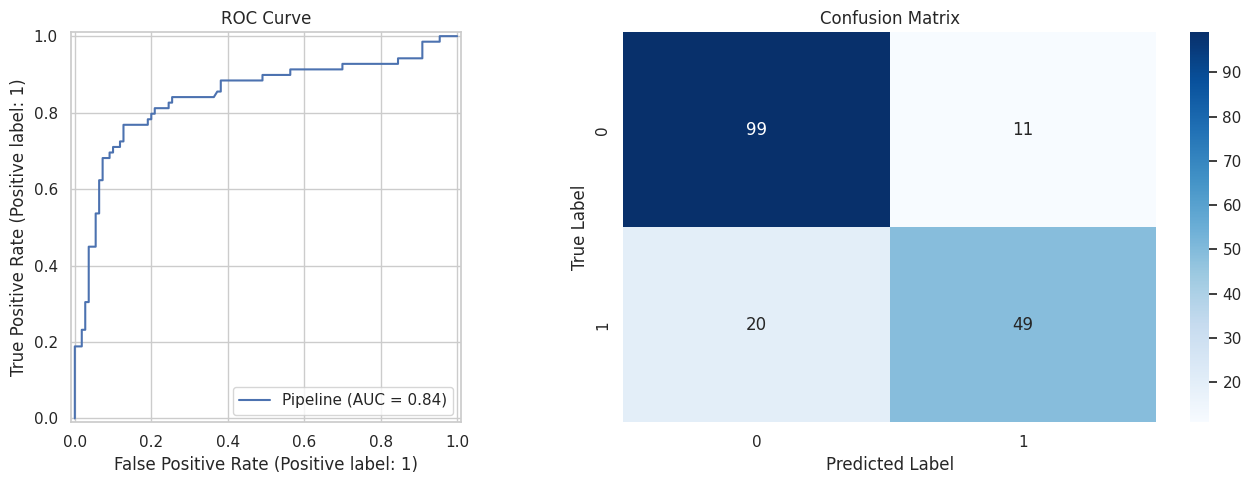

In [17]:
# Predizioni con il modello ottimizzato
y_pred_best = best_model.predict(X_test)
y_prob_best = best_model.predict_proba(X_test)[:, 1]

# Report di classificazione
print("Classification Report:")
print(classification_report(y_test, y_pred_best))

# ROC-AUC Score
roc_auc = roc_auc_score(y_test, y_prob_best)
print(f"ROC-AUC Score: {roc_auc:.4f}")

# Visualizzazione della Curva ROC e della Matrice di Confusione
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ROC Curve
RocCurveDisplay.from_estimator(best_model, X_test, y_test, ax=axes[0])
axes[0].set_title("ROC Curve")

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred_best)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[1])
axes[1].set_title("Confusion Matrix")
axes[1].set_xlabel("Predicted Label")
axes[1].set_ylabel("True Label")

plt.tight_layout()
plt.show()

#Section 8. Stress Test & What-If Analysis
##Let's see how the model behaves if we introduce noise or slightly alter the original test data (by simulating input errors or corrupted data):

In [19]:
# Section 8. Stress Test and What-If Analysis
import copy

# Creiamo una copia del test set per lo stress test
X_test_stressed = X_test.copy()

# Aggiungiamo un piccolo disturbo casuale (rumore) alle feature numeriche 'age' e 'fare'
np.random.seed(42)
X_test_stressed['age'] = X_test_stressed['age'] + np.random.normal(0, 5, size=len(X_test_stressed))
X_test_stressed['fare'] = X_test_stressed['fare'] * np.random.uniform(0.8, 1.2, size=len(X_test_stressed))

# Valutiamo il modello sul dataset stressato
y_pred_stressed = best_model.predict(X_test_stressed)
roc_auc_stressed = roc_auc_score(y_test, best_model.predict_proba(X_test_stressed)[:, 1])

print("--- STRESS TEST RESULTS ---")
print(f"ROC-AUC originale: {roc_auc:.4f}")
print(f"ROC-AUC post-stress: {roc_auc_stressed:.4f}")
print("\nClassification Report sotto stress:")
print(classification_report(y_test, y_pred_stressed))

#What-If Scenario
# Creiamo passeggeri ipotetici basati sulla struttura del dataset
# Colonne: ['pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked', 'who', 'adult_male', 'alone']

passenger_1 = pd.DataFrame([{
    'pclass': 3, 'sex': 'male', 'age': 25.0, 'sibsp': 0, 'parch': 0,
    'fare': 7.25, 'embarked': 'S', 'who': 'man', 'adult_male': True, 'alone': True
}])

passenger_2 = passenger_1.copy()
# WHAT-IF: E se fosse in prima classe (pclass=1) e pagasse un biglietto molto più alto?
passenger_2['pclass'] = 1
passenger_2['fare'] = 150.0

# Eseguiamo le predizioni e stimiamo le probabilità
prob_1 = best_model.predict_proba(passenger_1)[0][1]
prob_2 = best_model.predict_proba(passenger_2)[0][1]

print("--- WHAT-IF ANALYSIS ---")
print(f"Probabilità di sopravvivenza (Passeggero Standard - 3° classe): {prob_1 * 100:.2f}%")
print(f"Probabilità di sopravvivenza (What-If: Spostato in 1° classe & tariffa alta): {prob_2 * 100:.2f}%")

--- STRESS TEST RESULTS ---
ROC-AUC originale: 0.8441
ROC-AUC post-stress: 0.8503

Classification Report sotto stress:
              precision    recall  f1-score   support

           0       0.80      0.91      0.85       110
           1       0.81      0.64      0.72        69

    accuracy                           0.80       179
   macro avg       0.81      0.77      0.78       179
weighted avg       0.81      0.80      0.80       179

--- WHAT-IF ANALYSIS ---
Probabilità di sopravvivenza (Passeggero Standard - 3° classe): 4.20%
Probabilità di sopravvivenza (What-If: Spostato in 1° classe & tariffa alta): 38.23%


# Section 9. Survival Evaluation

## Assess Your Own Chance of Survival
Ever wondered how you would fare on the Titanic? In this section, you can input your own hypothetical details (such as age, passenger class, and gender) to see how this trained machine learning model predicts your chances of survival.

In [21]:
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

# 1. Caricamento di un dataset Titanic di pubblico dominio tramite seaborn o url
import seaborn as sns
df_titanic = sns.load_dataset('titanic')

# 2. Pulizia e Preparazione dei dati (EDA & Preprocessing essenziale)
# Selezioniamo le feature più importanti: pclass, sex, age, fare, embarked, alone
df_titanic = df_titanic[['survived', 'pclass', 'sex', 'age', 'fare', 'embarked', 'alone']].dropna()

# Codifica delle variabili categoriche (testuali) in numeriche
le_sex = LabelEncoder()
le_embarked = LabelEncoder()

df_titanic['sex'] = le_sex.fit_transform(df_titanic['sex']) # es. male=1, female=0
df_titanic['embarked'] = le_embarked.fit_transform(df_titanic['embarked'])
df_titanic['alone'] = df_titanic['alone'].astype(int)

# 3. Separazione Features (X) e Target (y)
X = df_titanic.drop('survived', axis=1)
y = df_titanic['survived']

# Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 4. Addestramento del Modello (Random Forest Classifier)
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

print(reale_score := f"Modello addestrato con successo! Accuratezza sul test set: {model.score(X_test, y_test):.2f}\n")

# ==========================================
# 5. WHAT-IF SCENARIO: INTERATTIVO
# ==========================================
def valuta_sopravvivenza():
    print("--- 🚢 WHAT-IF SCENARIO: IL TUO DESTINO SUL TITANIC ---")
    try:
        pclass = int(input("Inserisci la classe del biglietto (1 = Prima, 2 = Seconda, 3 = Terza): "))
        sex_str = input("Inserisci il genere (male / female): ").strip().lower()
        age = float(input("Inserisci la tua età (es. 25): "))
        fare = float(input("Inserisci quanto hai pagato il biglietto in sterline (es. 32.5): "))
        embarked_str = input("Porto di imbarco (C = Cherbourg, Q = Queenstown, S = Southampton): ").strip().upper()
        alone_input = input("Viaggiavi da solo/a? (s/n): ").strip().lower()

        # Conversione degli input utente nello stesso formato del dataset
        sex = 1 if sex_str == 'male' else 0

        # Gestione encoding embarked
        if embarked_str == 'C': embarked = 0
        elif embarked_str == 'Q': embarked = 1
        else: embarked = 2

        alone = 1 if alone_input == 's' else 0

        # Creazione del dataframe per la predizione
        input_utente = pd.DataFrame([[pclass, sex, age, fare, embarked, alone]],
                                    columns=['pclass', 'sex', 'age', 'fare', 'embarked', 'alone'])

        # Predizione
        predizione = model.predict(input_utente)[0]
        probabilita = model.predict_proba(input_utente)[0]

        print("\n" + "="*40)
        if predizione == 1:
            print(f"🎉 ESITO: ** SOPRAVVISSUTO/A **")
            print(f"Probabilità stimata di salvezza: {probabilita[1]*100:.1f}%")
        else:
            print(f"💀 ESITO: ** NON SOPRAVVISSUTO/A **")
            print(f"Probabilità stimata di decesso: {probabilita[0]*100:.1f}%")
        print("="*40)

    except Exception as e:
        print(f"Errore nell'inserimento dei dati: {e}. Riprova.")

# Esegui la funzione per testare lo scenario what-if
valuta_sopravvivenza()

Modello addestrato con successo! Accuratezza sul test set: 0.77

--- 🚢 WHAT-IF SCENARIO: IL TUO DESTINO SUL TITANIC ---
Inserisci la classe del biglietto (1 = Prima, 2 = Seconda, 3 = Terza): 1
Inserisci il genere (male / female): m
Inserisci la tua età (es. 25): 30
Inserisci quanto hai pagato il biglietto in sterline (es. 32.5): 200
Porto di imbarco (C = Cherbourg, Q = Queenstown, S = Southampton): s
Viaggiavi da solo/a? (s/n): s

🎉 ESITO: ** SOPRAVVISSUTO/A **
Probabilità stimata di salvezza: 100.0%
